# **Arena**

## **Section 1: Setting directory and preparing the dataset**

In [ ]:
%pip install -q torch==2.10.0 torchvision==0.25.0 --index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 133.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 165.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 216.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 62.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 72.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 120.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 185.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 103.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 114.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 107.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 109.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.1/139.1 MB 138.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
%%capture
!pip install torchmetrics
!pip install pkbar
!pip install calflops
!pip install torchinfo
!pip install grad-cam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Drive Directory**

In [ ]:
import os
import zipfile
import json
import pandas as pd
import numpy as np
import random as rd
import shutil
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torchvision
from torchvision.transforms import v2, InterpolationMode
import timm
import calflops
from functools import partial

In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
dataset_name = 'MushroomB'
dataset_drive_dir = f'{drive_dir}/data/{dataset_name}'

model_name_path = 'convnext_tiny_224_r1_v3' # เปลี่ยนเสมอ
model_name = 'ConvNeXt-Tiny' # เปลี่ยนเสมอ
sigle_model_title = f'{model_name} on {dataset_name} Dataset'
ensemble_model_title = f'{model_name} Ensemble on {dataset_name} Dataset'
model_dir = os.path.join(drive_dir, f'modelWeights/{dataset_name}', f"{model_name_path}_{dataset_name}")
model_ensem_dir = f'{model_dir}/ensemble'
model_summary_dir = f'{model_dir}/summary'

os.makedirs(model_dir, exist_ok=True)
font_dir = f'{drive_dir}/assets/fonts'

os.chdir(f'{drive_dir}')
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


**Runtime Directory**

In [ ]:
import src.reproducibility as reproducibility
import src.utils as utils
import src.datasets as datasets
import src.train as train
import src.test as test
import src.visualization as visualization
import src.gradCam as gradCam
import models.models as models

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')
def callbacks_fn(n_fold, fold_dir):
    checkpoint_path = f'{fold_dir}/{model_name_path}_{dataset_name}_best_weight.pth'
    return [utils.ModelCheckpoint(save_path=checkpoint_path, monitor=train.train_config['monitor'], mode=train.train_config['monitor_mode'])]

/usr/local/lib/python3.13/dist-packages/pkbar/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [ ]:
runtime_dir = '/content'
dataset_dir = f'{runtime_dir}/{dataset_name}'
os.makedirs(dataset_dir, exist_ok=True)

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Running on {device}.')
!python3 --version
!nvidia-smi

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
Running on cuda.
Python 3.13.15
Mon Oct  5 11:32:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   46C    P8             15W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         | 

**Load data from G-Drive**

In [ ]:
with zipfile.ZipFile(f'{dataset_drive_dir}/{dataset_name}_SPLIT_KEEP_DUP.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

remain_classes = set(os.listdir(f'{dataset_dir}/remain'))
test_classes = set(os.listdir(f'{dataset_dir}/test'))
unique_classes = remain_classes.union(test_classes)
NUM_CLASSES = len(unique_classes)
print(f'Number of classes: {NUM_CLASSES}')
print(f'Dataset has been extracted to {dataset_dir}')

Number of classes: 16
Dataset has been extracted to /content/MushroomB


## **Section 2: Define model architecture**

In [ ]:
model_fn = partial(
    models.build_baseline_model,
    model_name=model_name,
    num_classes=NUM_CLASSES,
    device=device,
    freeze_backbone=False
)
model = model_fn()

criterion = nn.CrossEntropyLoss()
optimizer_fn = lambda m : optim.AdamW(m.parameters(), lr=train.train_config['base_lr'], weight_decay=train.train_config['weight_decay'])
scheduler_fn = partial(optim.lr_scheduler.CosineAnnealingLR, T_max=train.train_config['max_epochs'])

model_config = models.get_transform_config(model)
summary(model, (1,) + model_config['input_size'], device=device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Layer (type:depth-idx)                             Output Shape              Param #
ConvNeXt                                           [1, 16]                   --
├─Sequential: 1-1                                  [1, 96, 56, 56]           --
│    └─Conv2d: 2-1                                 [1, 96, 56, 56]           4,704
│    └─LayerNorm2d: 2-2                            [1, 96, 56, 56]           192
├─Sequential: 1-2                                  [1, 768, 7, 7]            --
│    └─ConvNeXtStage: 2-3                          [1, 96, 56, 56]           --
│    │    └─Identity: 3-1                          [1, 96, 56, 56]           --
│    │    └─Sequential: 3-2                        [1, 96, 56, 56]           237,888
│    └─ConvNeXtStage: 2-4                          [1, 192, 28, 28]          --
│    │    └─Sequential: 3-3                        [1, 192, 28, 28]          74,112
│    │    └─Sequential: 3-4                        [1, 192, 28, 28]          918,144
│    └─ConvNeXtSt

## **Section 3: Preparing the dataset**

**Configuration for training**

In [ ]:
img_size = model_config['img_size']
resize_size = int(img_size[0] / model_config['crop_pct'])
interp_mode = getattr(InterpolationMode, model_config['interpolation'].upper())
num_workers = min(4, os.cpu_count())

print(f'Image size: {img_size}')
print(f'Resize size: {resize_size}')
print(f'Interpolation mode: {interp_mode}')
print(f'Number of workers: {num_workers}')

reproducibility.global_seed(seed=train.train_config['seed'])
reproducibility.training_seed(seed=train.train_config['seed'])
g = reproducibility.get_generator(seed=train.train_config['seed'])

Image size: (224, 224)
Resize size: 256
Interpolation mode: InterpolationMode.BICUBIC
Number of workers: 4
Global Seed set to: 42
Training Seed set to: 42


In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(img_size, scale=(0.3, 1.0), interpolation=interp_mode),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std']),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
])

transform = v2.Compose([
    v2.Resize(resize_size, interpolation=interp_mode, max_size=None, antialias=True),
    v2.CenterCrop(img_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=model_config['mean'], std=model_config['std'])
])

dataloader_kwargs = {
    'batch_size': train.train_config['batch_size'],
    'num_workers': num_workers,
    'worker_init_fn': reproducibility.seed_worker,
    'generator': g,
    'pin_memory': True
}

datasets = datasets.Datasets(
    dataset_dir=dataset_dir,
    train_transform=train_transform,
    transform=transform,
    dataloader_kwargs=dataloader_kwargs,
)

datasets.print_summary()
test_loader = datasets.get_test_loader()

--------------------------------------------------
Dataset Summary
--------------------------------------------------
Class names       : ['Amanita_Caesarea-Edible', 'Amanita_Citrina-Edible', 'Amanita_Pantherina-NotEdible', 'Boletus_Regius-Edible', 'Clitocybe_Costata-Edible', 'Entoloma_Lividum-NotEdible', 'Gyromitra_Esculenta-NotEdible', 'Helvella_Crispa-Edible', 'Hydnum_Rufescens-NotEdible', 'Hygrophorus_Latitabundus-Edible', 'Morchella_Deliciosa-Edible', 'Omphalotus_Olearius-NotEdible', 'Phallus_Impudicus-NotEdible', 'Rubroboletus_Satanas-NotEdible', 'Russula_Cyanoxantha-Edible', 'Russula_Delica-NotEdible']
Class to Index    : {'Amanita_Caesarea-Edible': 0, 'Amanita_Citrina-Edible': 1, 'Amanita_Pantherina-NotEdible': 2, 'Boletus_Regius-Edible': 3, 'Clitocybe_Costata-Edible': 4, 'Entoloma_Lividum-NotEdible': 5, 'Gyromitra_Esculenta-NotEdible': 6, 'Helvella_Crispa-Edible': 7, 'Hydnum_Rufescens-NotEdible': 8, 'Hygrophorus_Latitabundus-Edible': 9, 'Morchella_Deliciosa-Edible': 10, 'Ompha

## **Section 4: Training the model**

In [ ]:
trainer = train.KFoldTrainer(
    n_splits=train.train_config['n_folds'],
    shuffle=True,
    random_state=train.train_config['seed'],
    model_name=model_name_path,
    dataset_name=dataset_name,
    base_dir=model_dir,
    first_metric=train.train_config['first_metric'],
    first_metric_mode=train.train_config['first_metric_mode'],
    secondary_metric=train.train_config['secondary_metric'],
    secondary_metric_mode=train.train_config['secondary_metric_mode'],
    device=device,
    criterion=criterion,
    n_classes=NUM_CLASSES,
    task=train.train_config['task'],
    average=train.train_config['average'],
    max_grad_norm=0.0
)

[Logs] Setup directories at '/content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB' successfully.


In [ ]:
fold_histories = trainer.fit_kfold(
    train_dataset=datasets.train_dataset,
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    model_fn=model_fn,
    optimizer_fn=optimizer_fn,
    epochs=train.train_config['max_epochs'],
    dataloader_kwargs=dataloader_kwargs,
    callbacks_fn=callbacks_fn,
    scheduler_fn=scheduler_fn
)

Starting Stratified 5-Fold Cross Validation

--------------------------------------------- FOLD 1/5 ---------------------------------------------
Epoch: 1/30
61/61 [==============================] - 26s 423ms/step - loss: 2.2315 - lr: 1.0000e-04 - accuracy: 0.4268 - f1: 0.3442 - precision: 0.4711 - recall: 0.3409
Epoch 1/30 | val_loss: 1.2263 - val_accuracy: 0.8306 - val_f1: 0.7748 - val_precision: 0.8698 - val_recall: 0.7741
[Logs] Epoch: 1 val_accuracy improved from -inf to 0.8306, saving model to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/fold_1/convnext_tiny_224_r1_v3_MushroomB_best_weight.pth
Epoch: 2/30
61/61 [==============================] - 18s 292ms/step - loss: 0.7491 - lr: 9.9726e-05 - accuracy: 0.9048 - f1: 0.8907 - precision: 0.9067 - recall: 0.8834
Epoch 2/30 | val_loss: 0.2979 - val_accuracy: 0.9711 - val_f1: 0.9679 - val_precision: 0.9694 - val_recall: 0.9688
[Logs] Epoch: 2 val_accuracy improved from 0.8306 to 0.971

## **Section 5: Individual model performance**

In [ ]:
y_true = test.get_true_label(test_loader, is_onehot=False)

### **Learning curve**

#### **Individual**

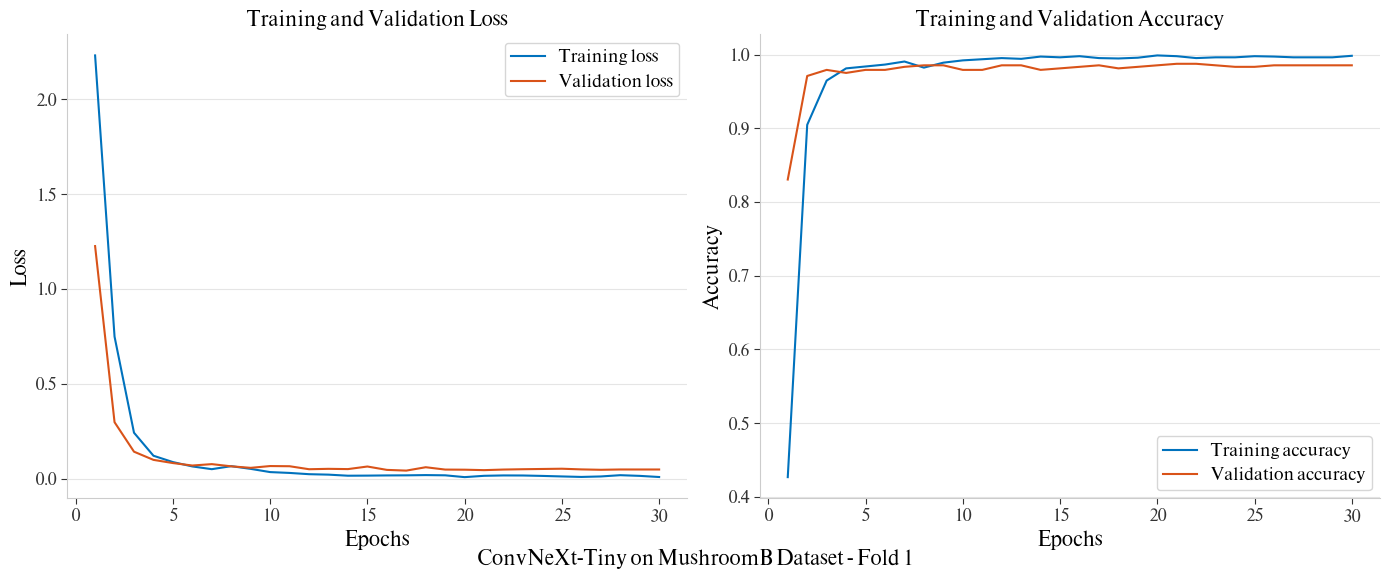

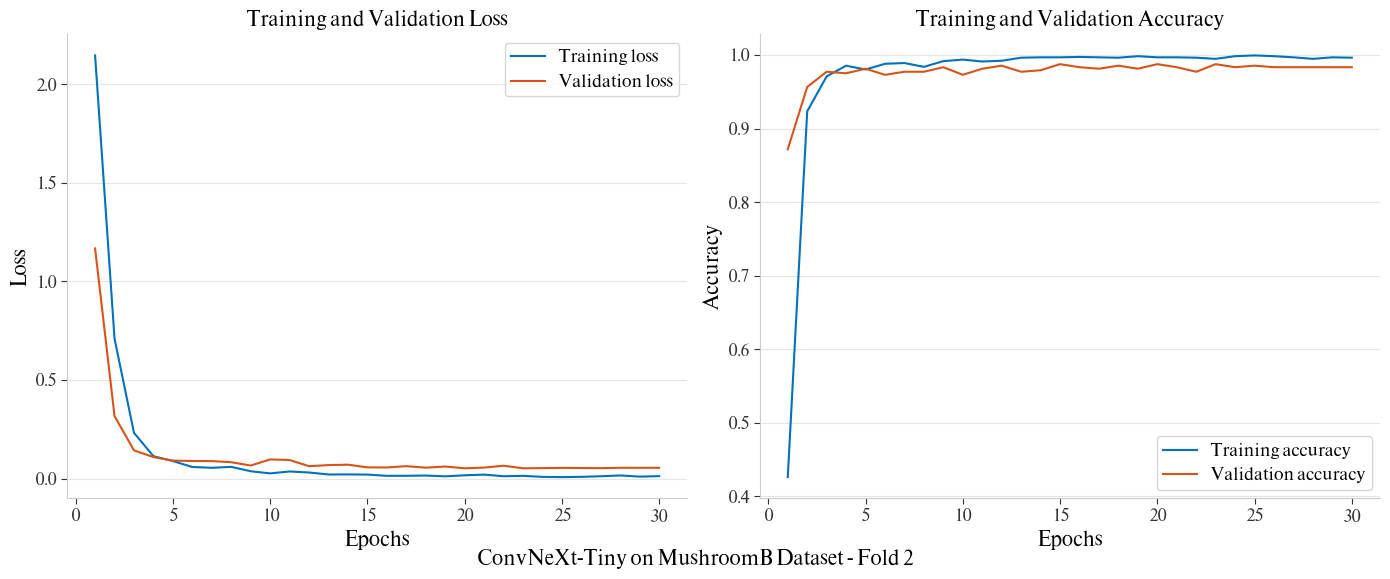

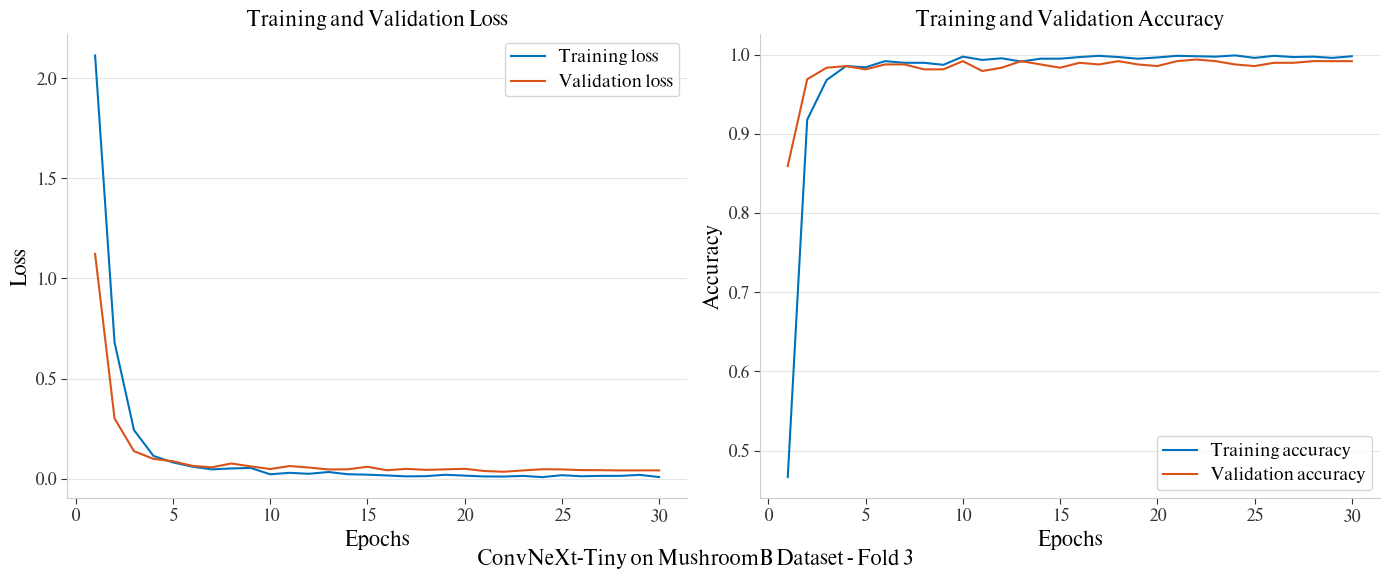

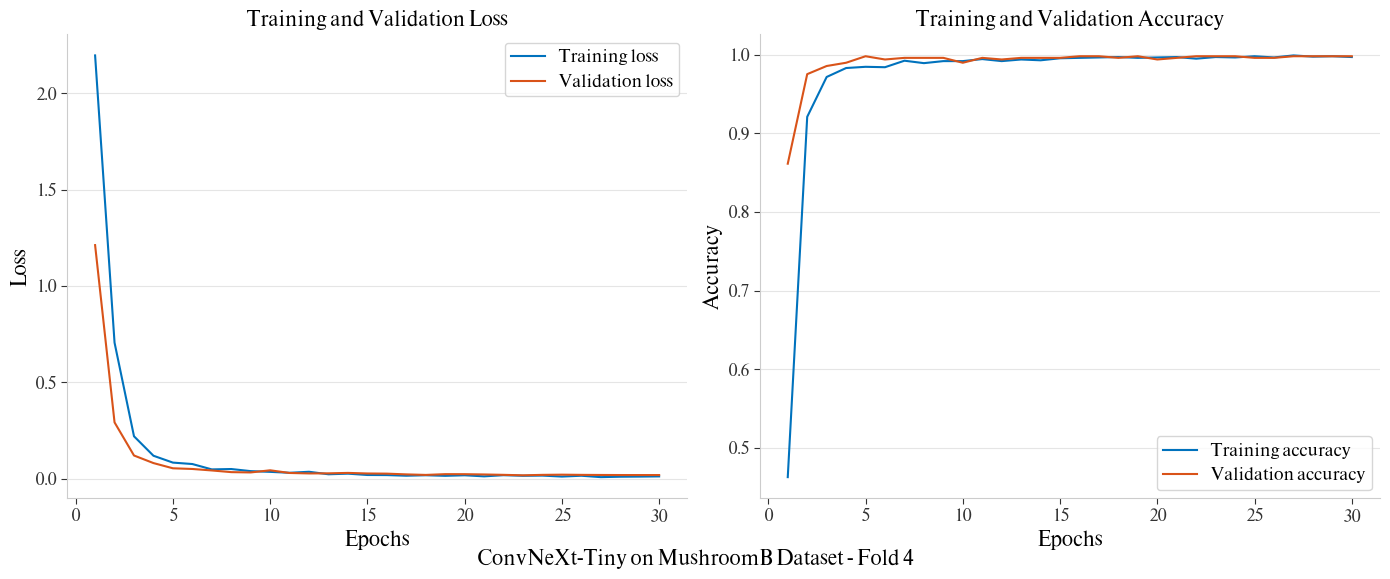

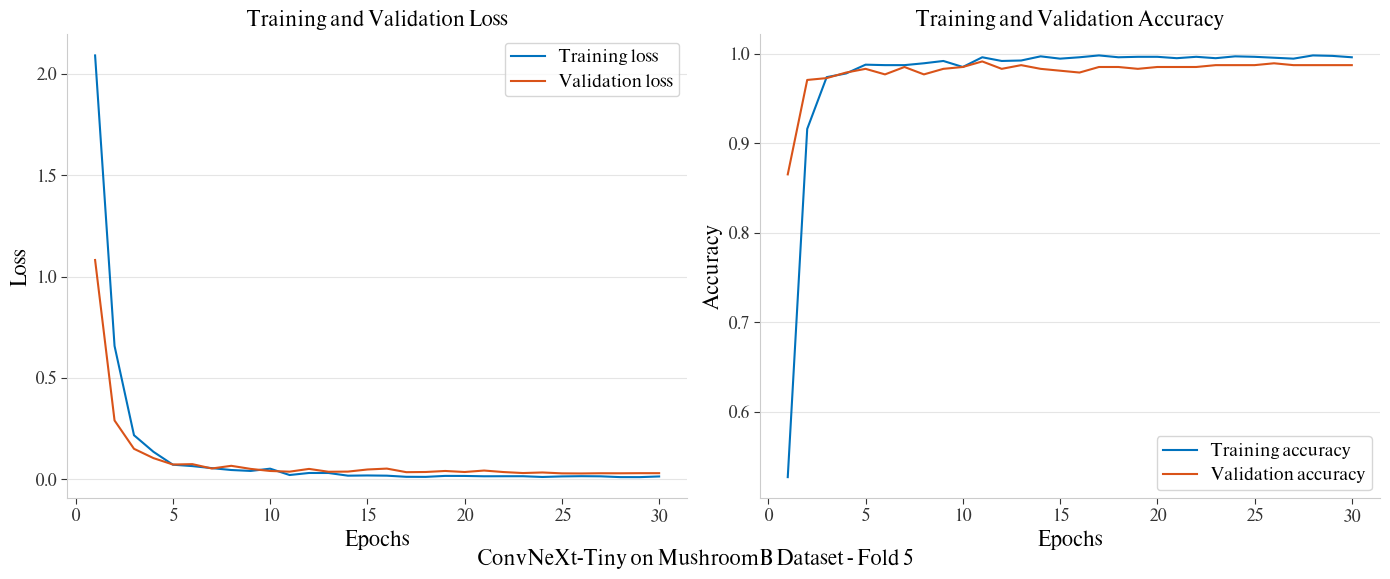

In [ ]:
for fold_key, history in fold_histories.items():
    fold_num = fold_key.split('_')[1]
    fold_dir = f"{trainer.base_dir}/fold_{fold_num}"

    visualization.plot_lr_curve(
        history=history,
        figsize=(14, 6),
        fontsize=14,
        title=f"{sigle_model_title} - Fold {fold_num}",
        save_path=fold_dir
    )

    print('\n')

#### **Overall**

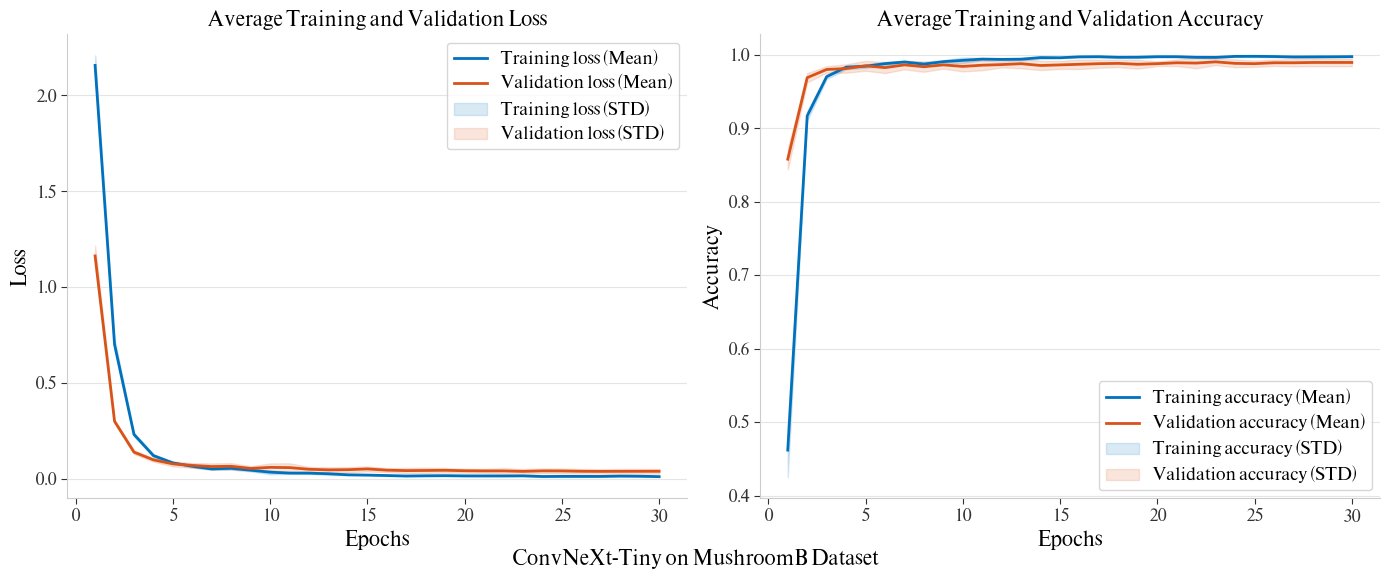

In [ ]:
visualization.plot_cv_summary_curve(
    histories=list(fold_histories.values()),
    figsize=(14, 6),
    fontsize=14,
    title=sigle_model_title,
    save_path=model_ensem_dir
)

### **On validation set**

In [ ]:
individual_validate_perf_df = trainer.evaluate_kfold(
    val_dataset=datasets.val_dataset,
    labels=datasets.all_classes,
    dataloader_kwargs=dataloader_kwargs,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type']
)

Evaluating 5-Fold Models on their respective Validation Sets (BEST weights)

[*] Evaluating Fold 1/5 on its Validation Set...
16/16 [==============================] - 3s 216ms/step - loss: 0.0451 - accuracy: 0.9876 - f1: 0.9862 - precision: 0.9851 - recall: 0.9881
[*] Evaluating Fold 2/5 on its Validation Set...
16/16 [==============================] - 4s 264ms/step - loss: 0.0565 - accuracy: 0.9876 - f1: 0.9848 - precision: 0.9858 - recall: 0.9842
[*] Evaluating Fold 3/5 on its Validation Set...
16/16 [==============================] - 4s 278ms/step - loss: 0.0349 - accuracy: 0.9938 - f1: 0.9938 - precision: 0.9954 - recall: 0.9924
[*] Evaluating Fold 4/5 on its Validation Set...
16/16 [==============================] - 4s 249ms/step - loss: 0.0540 - accuracy: 0.9979 - f1: 0.9972 - precision: 0.9975 - recall: 0.9970
[*] Evaluating Fold 5/5 on its Validation Set...
16/16 [==============================] - 4s 251ms/step - loss: 0.0381 - accuracy: 0.9917 - f1: 0.9901 - precision: 0.9906 

### **On test set**

In [ ]:
ensemble_probs, timing_report = trainer.predict_kfold(
    dataloader=test_loader,
    model_fn=model_fn,
    weight_type=train.train_config['weight_type'],
    timer_report_dict=True,
    verbose=1
)

Ensemble Prediction using 5-Fold Models (BEST weights)

[*] Running inference for Fold 1/5...
19/19 [==============================] - 7s 382ms/step

[Inference Report] Latency: 163.42 ms/batch | Throughput: 193.23 samples/sec
    -> Saved fold 1 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/fold_1/fold_1_infer_timing_report.csv
    -> Saved fold 1 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/fold_1/fold_1_test_probs_best_weight.csv
[*] Running inference for Fold 2/5...
19/19 [==============================] - 5s 269ms/step

[Inference Report] Latency: 54.35 ms/batch | Throughput: 581.01 samples/sec
    -> Saved fold 2 timing report to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/fold_2/fold_2_infer_timing_report.csv
    -> Saved fold 2 predictions to /content/drive/MyDrive/projectMushroom/modelWeights/Mu

In [ ]:
individual_test_perf_df = test.evaluate_preds_kfold(
    base_dir=model_dir,
    n_splits=train.train_config['n_folds'],
    y_true=y_true,
    weight_type=train.train_config['weight_type'],
    task=train.train_config['task'],
    average=train.train_config['average'],
)

[*] Fold 1/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 2/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 3/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 4/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro
[*] Fold 5/5 | Shape: (600, 16)
[*] Task Type: Multiclass | Average: macro

----------------------------------------------------------------------------------------------------
K-Fold Test Set Evaluation Results (Individual Models):
  Fold     loss  accuracy       f1  precision   recall
Fold 1 0.063778  0.985000 0.983550   0.984380 0.983513
Fold 2 0.071016  0.980000 0.976602   0.977432 0.976792
Fold 3 0.054232  0.988333 0.986436   0.987071 0.986242
Fold 4 0.086767  0.985000 0.983763   0.984351 0.983559
Fold 5 0.061321  0.981667 0.979484   0.981006 0.978763
  Mean 0.067423  0.984000 0.981967   0.982848 0.981774
   STD 0.012365  0.003249 0.003894   0.003714 0.003875
---------------------------

## **Section 6: Ensemble model performance**

### **On test set**

In [ ]:
y_pred, metrics = test.evaluate_preds(
    y_true=y_true,
    y_probs=ensemble_probs,
    task=train.train_config['task'],
    average=train.train_config['average'],
    save_path=f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv'
)

[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble/ensem_test_perf_best_weight.csv


### **Classification report**

In [ ]:
report = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name)

report_dict = classification_report(y_true, y_pred, digits=4, target_names=datasets.classes_name, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(f'{model_ensem_dir}/ensem_classification_report.csv')

print('Classification Report on Ensemble')
print('=' * 100)
print(report)

Classification Report on Ensemble
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     1.0000    1.0000    1.0000        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9630    0.9811        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Latitabundus-Edible     1.0000    1.0000    1.0000        26
     Morchella_Deliciosa-Edible     0.9800    1.0000    0.9899        49
  Omphalotus_Olearius-NotEdible     1.0000    1.0000    1.0000        29
    Phallus_Impu

### **Correct predictions**

In [ ]:
df_correct, df_incorrect = test.pred_records(
    y_true=y_true,
    y_pred=y_pred,
    y_probs=ensemble_probs,
    filepaths=[path for path, _ in test_loader.dataset.samples],
    idx_to_class=datasets.idx_to_class,
    save_dir=f'{model_ensem_dir}',
    prefix='ensem'
)

In [ ]:
df_correct

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997021
1,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997926
2,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.995574
3,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.996499
4,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997687
...,...,...,...,...,...,...
590,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.993703
591,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.990651
592,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.994157
593,/content/MushroomB/test/Russula_Delica-NotEdib...,Russula_Delica-NotEdible,Russula_Delica-NotEdible,15,15,0.982551


### **Incorrect predictions**

In [ ]:
df_incorrect

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Amanita_Citrina-Edible...,Russula_Delica-NotEdible,Amanita_Citrina-Edible,15,1,0.470476
1,/content/MushroomB/test/Amanita_Citrina-Edible...,Amanita_Pantherina-NotEdible,Amanita_Citrina-Edible,2,1,0.693668
2,/content/MushroomB/test/Clitocybe_Costata-Edib...,Entoloma_Lividum-NotEdible,Clitocybe_Costata-Edible,5,4,0.941063
3,/content/MushroomB/test/Gyromitra_Esculenta-No...,Morchella_Deliciosa-Edible,Gyromitra_Esculenta-NotEdible,10,6,0.993659
4,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Delica-NotEdible,Russula_Cyanoxantha-Edible,15,14,0.555641


### **Confusion matrix**

#### **without Normalize**

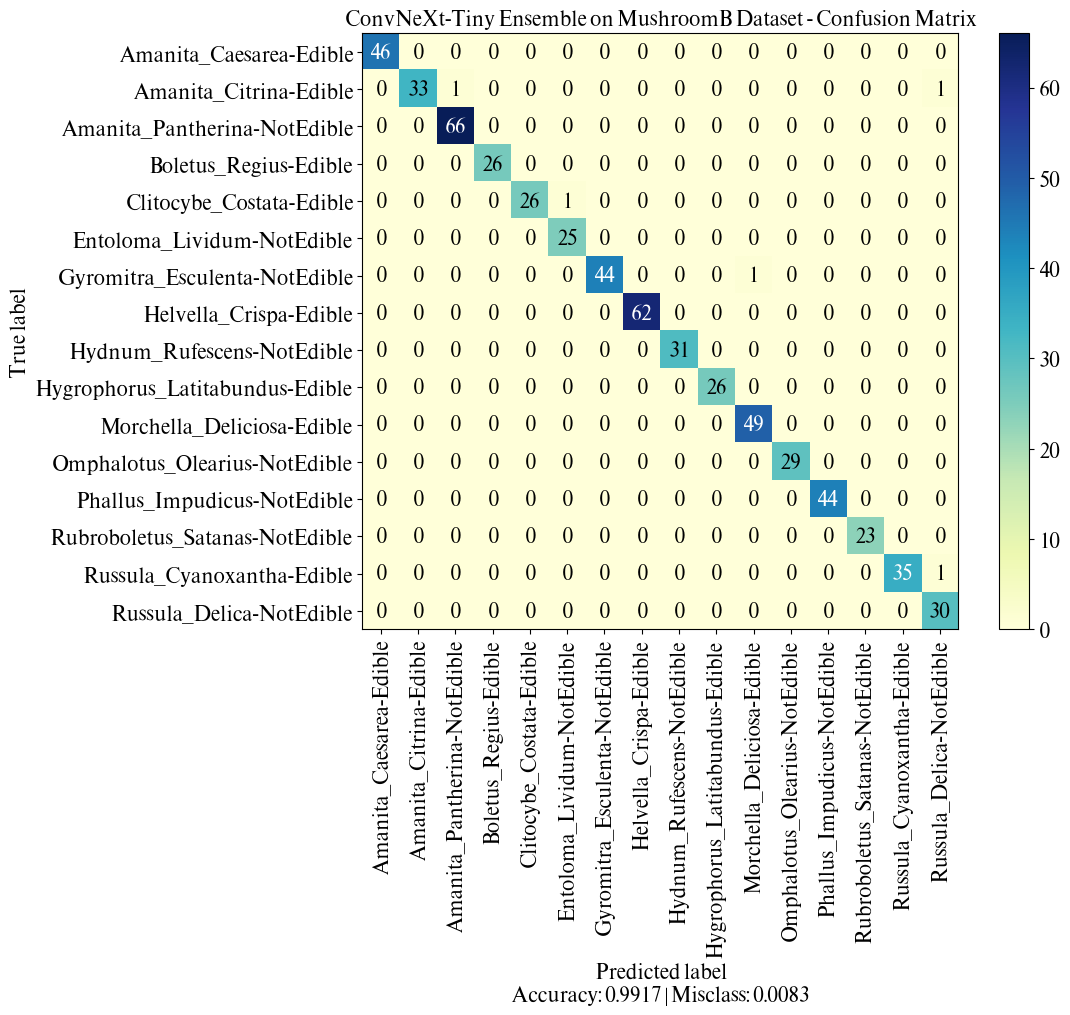

In [ ]:
cm = confusion_matrix(y_true, y_pred)
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=False,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

#### **with Normalize**

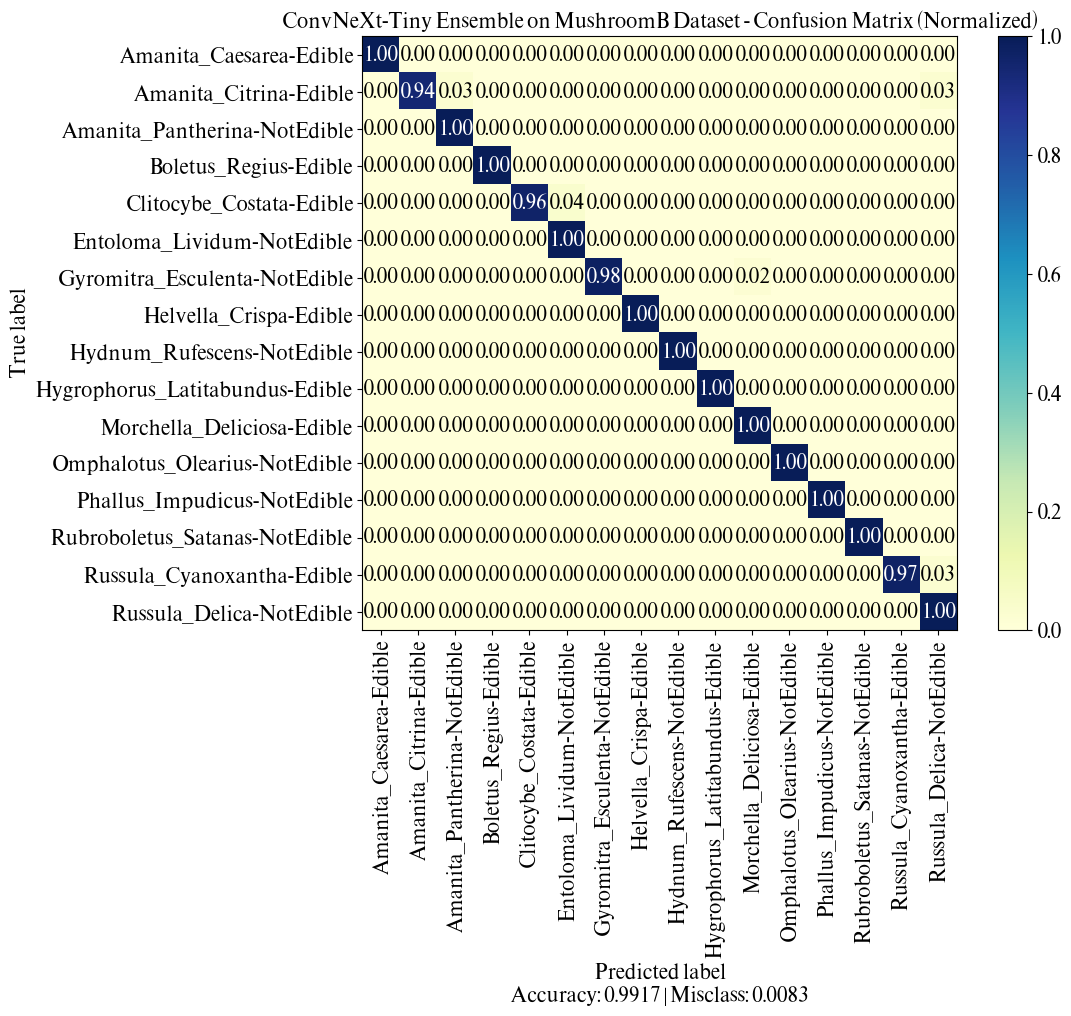

In [ ]:
visualization.plot_confusion_matrix(
    cm=cm,
    class_names=datasets.classes_name,
    norm=True,
    cmap=plt.cm.YlGnBu,
    task=train.train_config['task'],
    figsize=(12, 10),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

### **ROC-AUC curve**

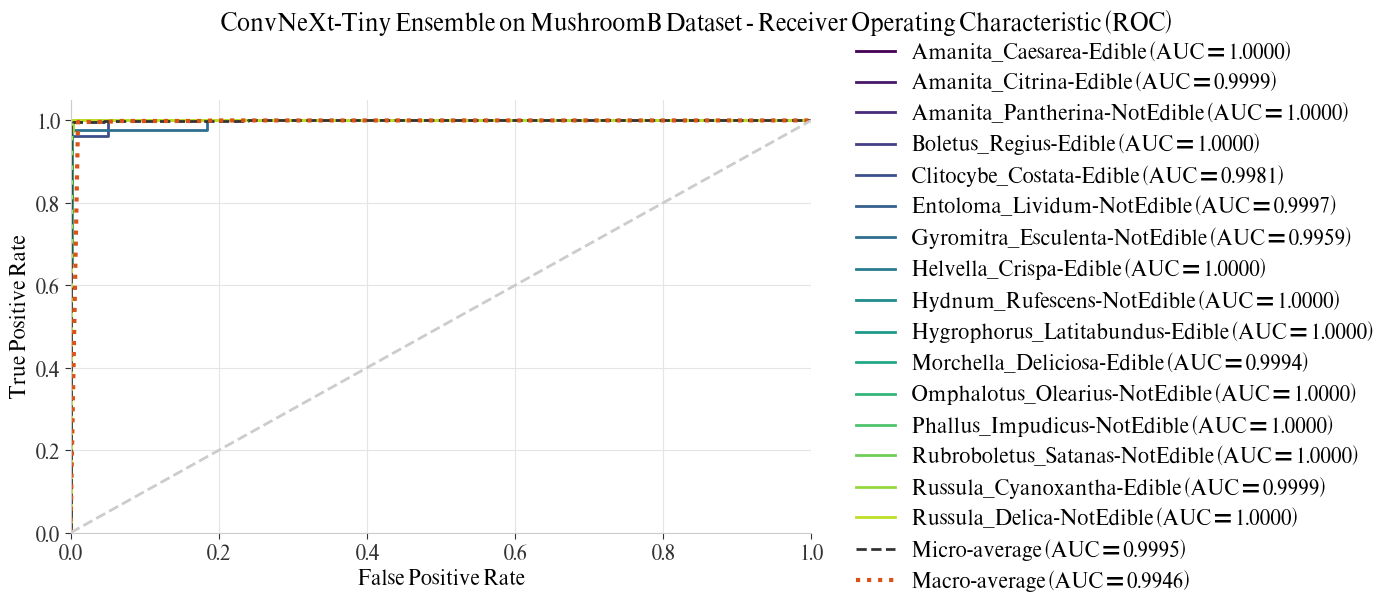

In [ ]:
visualization.plot_roc_auc_curve(
    y_true=y_true,
    y_pred_probs=ensemble_probs,
    class_names=datasets.classes_name,
    task=train.train_config['task'],
    legend_ncol=1,
    figsize=(14, 6),
    fontsize=14,
    title=ensemble_model_title,
    save_path=model_ensem_dir
)

## **Section 7: Grad-CAM**

In [ ]:
best_model, best_fold_dir, best_fold_num = trainer.get_best_model_on_validate_set(model_fn=model_fn)
target_layers = [best_model.stages[-1].blocks[-1]]
print(target_layers)

[Logs] Retrieving Best Model from Fold 4
       Primary Metric: accuracy->0.9979 | Secondary: loss->0.0540 on Validation set.
[ConvNeXtBlock(
  (conv_dw): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (shortcut): Identity()
  (drop_path): Identity()
)]


In [ ]:
unique_label = pd.read_csv(f'{dataset_drive_dir}/unique_label.csv')
unique_label

,Filepaths,Pred_Label,True_Label,Pred_Index,True_Index,Prob
0,/content/MushroomB/test/Boletus_Regius-Edible/...,Boletus_Regius-Edible,Boletus_Regius-Edible,3,3,0.997353
1,/content/MushroomB/test/Amanita_Pantherina-Not...,Amanita_Pantherina-NotEdible,Amanita_Pantherina-NotEdible,2,2,0.998482
2,/content/MushroomB/test/Russula_Cyanoxantha-Ed...,Russula_Cyanoxantha-Edible,Russula_Cyanoxantha-Edible,14,14,0.996642
3,/content/MushroomB/test/Helvella_Crispa-Edible...,Helvella_Crispa-Edible,Helvella_Crispa-Edible,7,7,0.998135
4,/content/MushroomB/test/Morchella_Deliciosa-Ed...,Morchella_Deliciosa-Edible,Morchella_Deliciosa-Edible,10,10,0.997952
5,/content/MushroomB/test/Amanita_Caesarea-Edibl...,Amanita_Caesarea-Edible,Amanita_Caesarea-Edible,0,0,0.997525
6,/content/MushroomB/test/Omphalotus_Olearius-No...,Omphalotus_Olearius-NotEdible,Omphalotus_Olearius-NotEdible,11,11,0.990162
7,/content/MushroomB/test/Hygrophorus_Latitabund...,Hygrophorus_Latitabundus-Edible,Hygrophorus_Latitabundus-Edible,9,9,0.994168
8,/content/MushroomB/test/Amanita_Citrina-Edible...,Amanita_Citrina-Edible,Amanita_Citrina-Edible,1,1,0.993885
9,/content/MushroomB/test/Entoloma_Lividum-NotEd...,Entoloma_Lividum-NotEdible,Entoloma_Lividum-NotEdible,5,5,0.901141


In [ ]:
gradCam.plot_grad_cam(
    model=best_model,
    target_layers=target_layers,
    df=unique_label[:9],
    filepaths_col='Filepaths',
    true_label_col='True_Label',
    true_idx='True_Index',
    device=device,
    transform=transform,
    task=train.train_config['task'],
    reshape_transform=None,
    img_size=model_config['img_size'],
    img_base_size=3,
    row_one_title=True,
    fontsize=24,
    save_path=model_ensem_dir,
    titlesize=13
)

Output hidden; open in https://colab.research.google.com to view.

## **Section 8: Summary**

##### **Performace on Validation Set (N Folds)**

In [ ]:
display(individual_validate_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.045139,0.987603,0.986177,0.985108,0.988082
Fold 2,0.056527,0.987603,0.984828,0.985818,0.984233
Fold 3,0.034942,0.993789,0.993819,0.995417,0.992445
Fold 4,0.053988,0.997930,0.997200,0.997500,0.997024
Fold 5,0.038091,0.991718,0.990122,0.990588,0.990184
Mean,0.045737,0.991729,0.990429,0.990886,0.990394
STD,0.009485,0.004380,0.005169,0.005555,0.004783


##### **Performace on Test Set (N Folds)**

In [ ]:
display(individual_test_perf_df.style.hide(axis="index"))

Fold,loss,accuracy,f1,precision,recall
Fold 1,0.063778,0.985000,0.983550,0.984380,0.983513
Fold 2,0.071016,0.980000,0.976602,0.977432,0.976792
Fold 3,0.054232,0.988333,0.986436,0.987071,0.986242
Fold 4,0.086767,0.985000,0.983763,0.984351,0.983559
Fold 5,0.061321,0.981667,0.979484,0.981006,0.978763
Mean,0.067423,0.984000,0.981967,0.982848,0.981774
STD,0.012365,0.003249,0.003894,0.003714,0.003875


##### **Performace on Test Set (Ensemble)**

In [ ]:
ensem_test_perf_df = pd.read_csv(f'{model_ensem_dir}/ensem_test_perf_{train.train_config['weight_type']}_weight.csv')
display(ensem_test_perf_df.style.hide(axis="index"))

loss,accuracy,f1,precision,recall
0.057392,0.991667,0.991057,0.991507,0.990989


#### **Model Info**

In [ ]:
flops, macs, params = calflops.calculate_flops(
    model=best_model,
    input_shape=(1,) + model_config['input_size'],
    output_precision=4,
    print_results=False
)

flops_val = float(flops.split()[0])
if 'MFLOPS' in flops:
    flops_val /= 1000.0
flops = f'{flops_val:.4f}'

macs_val = float(macs.split()[0])
if 'MMACs' in macs:
    macs_val /= 1000.0
macs = f'{macs_val:.4f}'

params_val = float(params.split()[0])
if 'K' in params:
    params_val /= 1000.0
elif 'B' in params:
    params_val *= 1000.0
params = f'{params_val:.4f}'

model_summary_report = {
    'Batch Size': [train.train_config['batch_size']],
    'Image Size': [f'{img_size[0]}\u00D7{img_size[1]}'],
    'GFLOPs': [flops],
    'GMACs': [macs],
    'Params (M)': [params],
    'Latency (ms/img)': timing_report['avg_single_model_latency_sample'],
    'Latency (ms/batch)': timing_report['avg_single_model_latency_batch'],
    'Throughput (img/s)': timing_report['avg_single_model_throughput'],
}

model_summary_df = pd.DataFrame(model_summary_report)
model_summary_df.to_csv(f'{model_summary_dir}/model_summary.csv', index=False)
display(model_summary_df.style.hide(axis="index"))

Batch Size,Image Size,GFLOPs,GMACs,Params (M),Latency (ms/img),Latency (ms/batch),Throughput (img/s)
32,224×224,8.9379,4.4548,27.8324,1.720287,54.324858,581.298952


## **Section 9: Addition**

##### **Preparation**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

add_drive_dir = '/content/drive/MyDrive/projectMushroom' # ตำแหน่ง Root Project Folder ใน G-Drive
add_dataset_name = 'MushroomB'

def get_model_dir(model_name_path, weights_root='modelWeights', dataset_name=add_dataset_name):
    return os.path.join(add_drive_dir, f'{weights_root}/{dataset_name}', f'{model_name_path}_{dataset_name}')

# Model of this notebook
add_weights_root = 'modelWeights'
add_model_name_path = 'convnext_tiny_224_r1_v3'
add_model_name = 'ConvNeXt-Tiny (Duplicate)'
add_model_dir = get_model_dir(add_model_name_path, weights_root=add_weights_root)

# McNemar's test: Baseline vs Proposed (Default proposed = model of this notebook)
mc_baseline_name = 'ConvNeXt-Tiny (Cleaning)'
mc_baseline_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')
mc_proposed_name = add_model_name
mc_proposed_model_dir = add_model_dir
mc_alpha = 0.05

add_config = {
    'n_folds': 5,
    'task': 'multiclass',
    'average': 'macro',
    'weight_type': 'best',
}

add_plot_kwargs = {
    'cmap': plt.cm.YlGnBu,
    'fontsize': 14,
}

In [3]:
os.chdir(add_drive_dir)
print(f'Current directory: {os.getcwd()}')
print(f'Model directory   : {add_model_dir}')
print(f'Baseline directory: {mc_baseline_model_dir}')
print(f'Proposed directory: {mc_proposed_model_dir}')

import src.visualization as visualization
import src.ensembleVoting as ensembleVoting
import src.mcnemarTest as mcnemarTest

visualization.matplotlib_font(font_dir=f'{add_drive_dir}/assets/fonts', prefer_name='Times-Roman')

Current directory: /content/drive/MyDrive/projectMushroom
Model directory   : /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB
Baseline directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v1_MushroomB
Proposed directory: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB


'OPTITimes-Roman'

##### **Compare voting strategies on test set**

[*] Loaded Fold 1/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 2/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 3/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 4/5 probabilities | Shape: (600, 16)
[*] Loaded Fold 5/5 probabilities | Shape: (600, 16)
[*] Recovered test order verified against /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble/ensem_test_probs_best_weight.csv
[*] Recovered 600 test samples | 16 classes
[Logs] Saved Voting Weights to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble_addition/voting_weights_best_weight.csv

Voting Method: SOFT
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble_addition/soft/soft_test_perf_best_weight.csv
                                 precision    recall  f1-score   support

        Amanita_Caesa

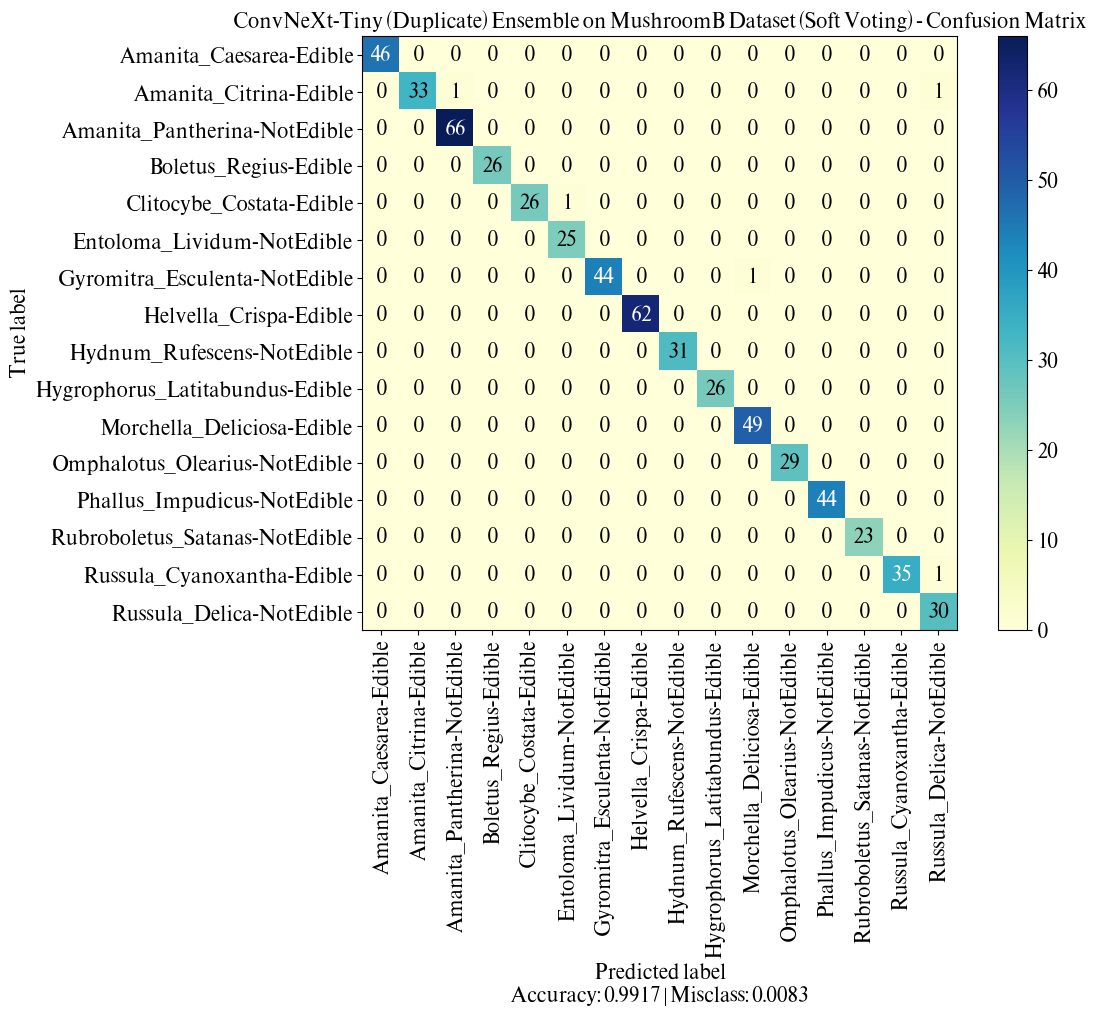

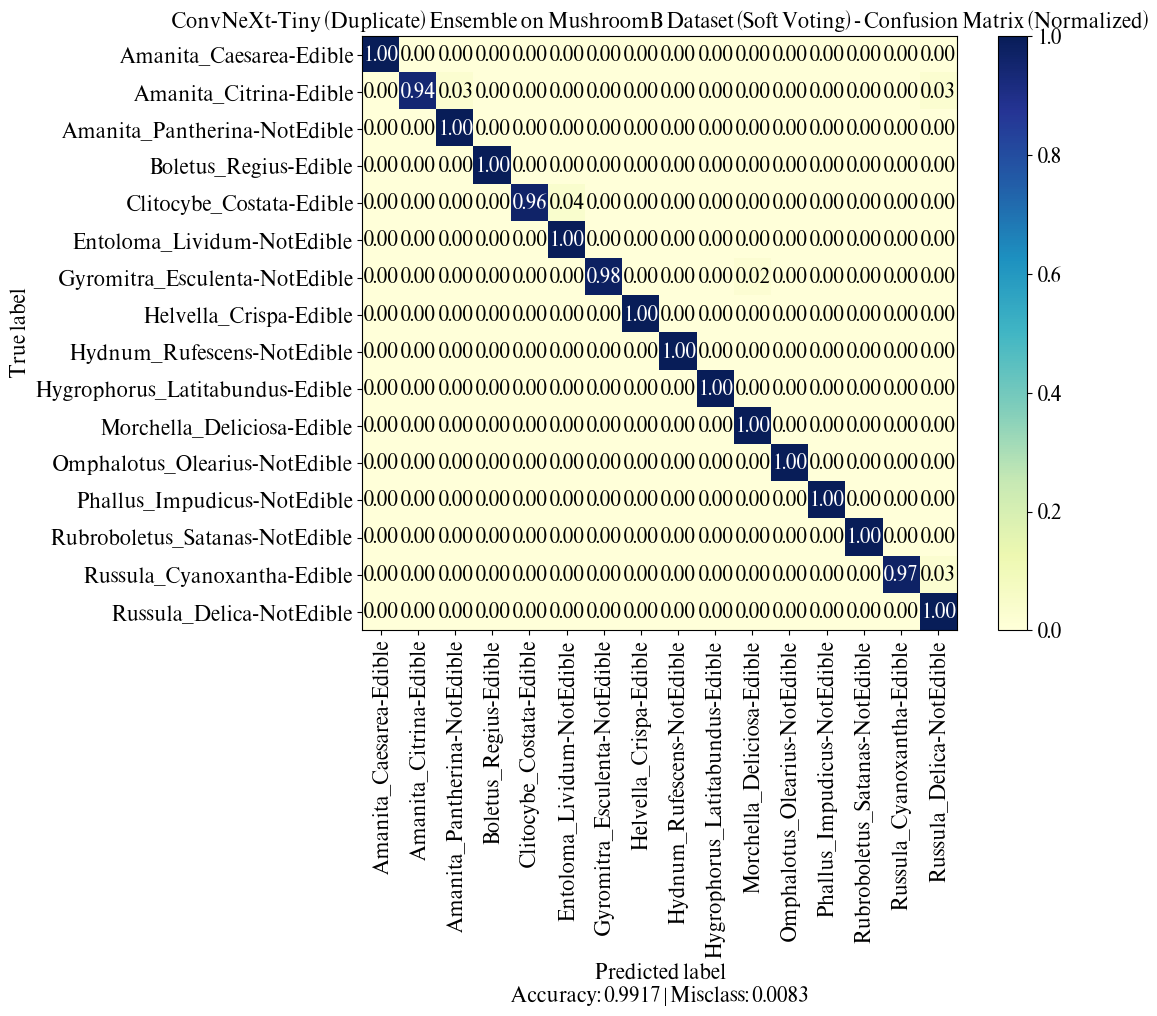

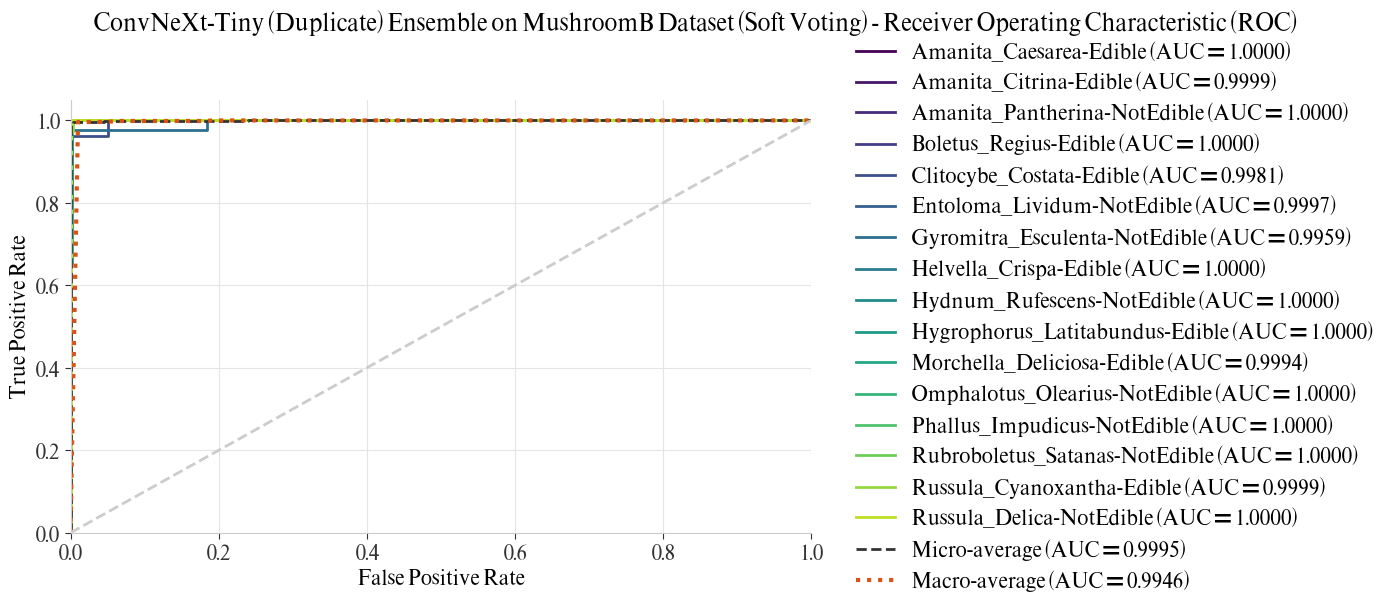




Voting Method: HARD
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble_addition/hard/hard_test_perf_best_weight.csv
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     1.0000    1.0000    1.0000        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9630    0.9811        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Latitabundus-Edible     1.0000    1.0000    1.0000        2

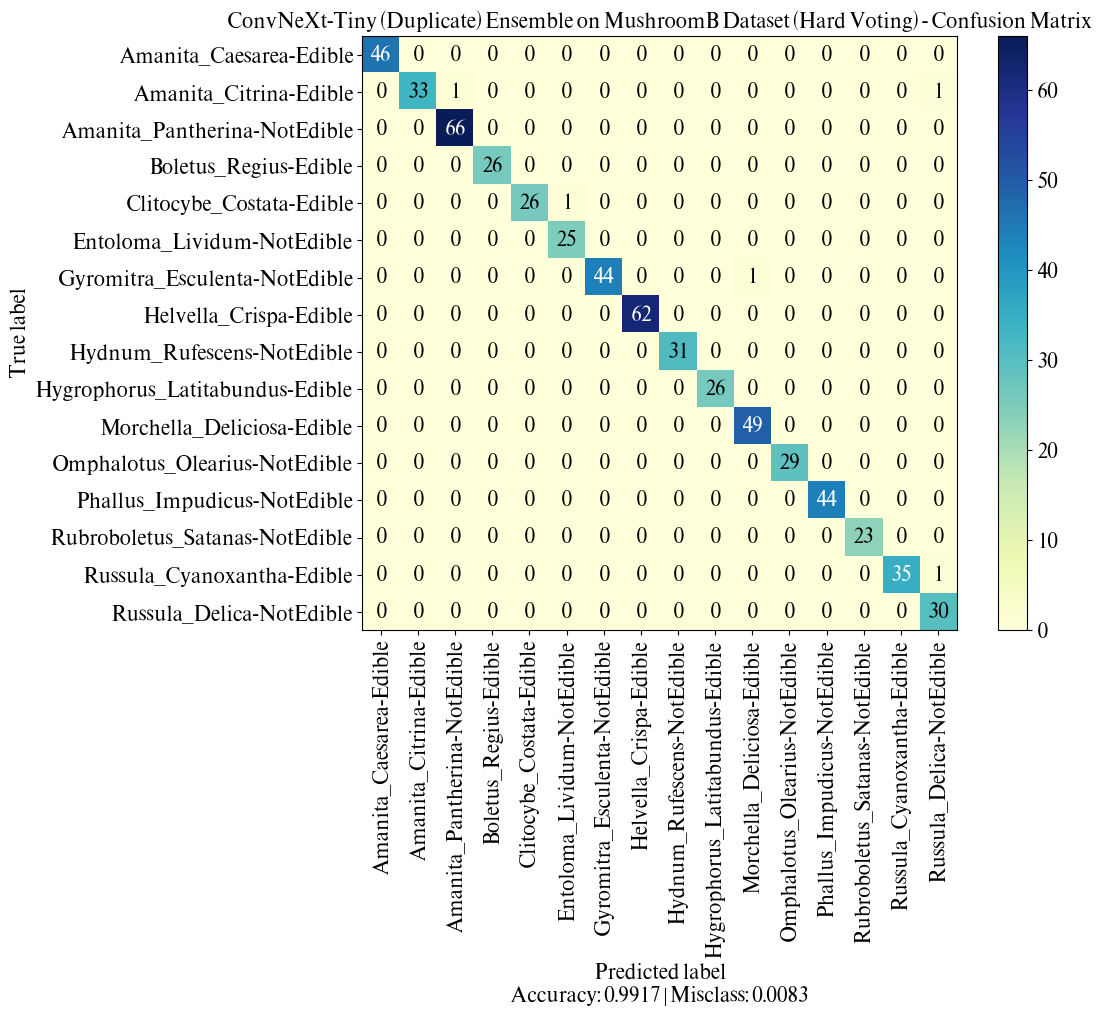

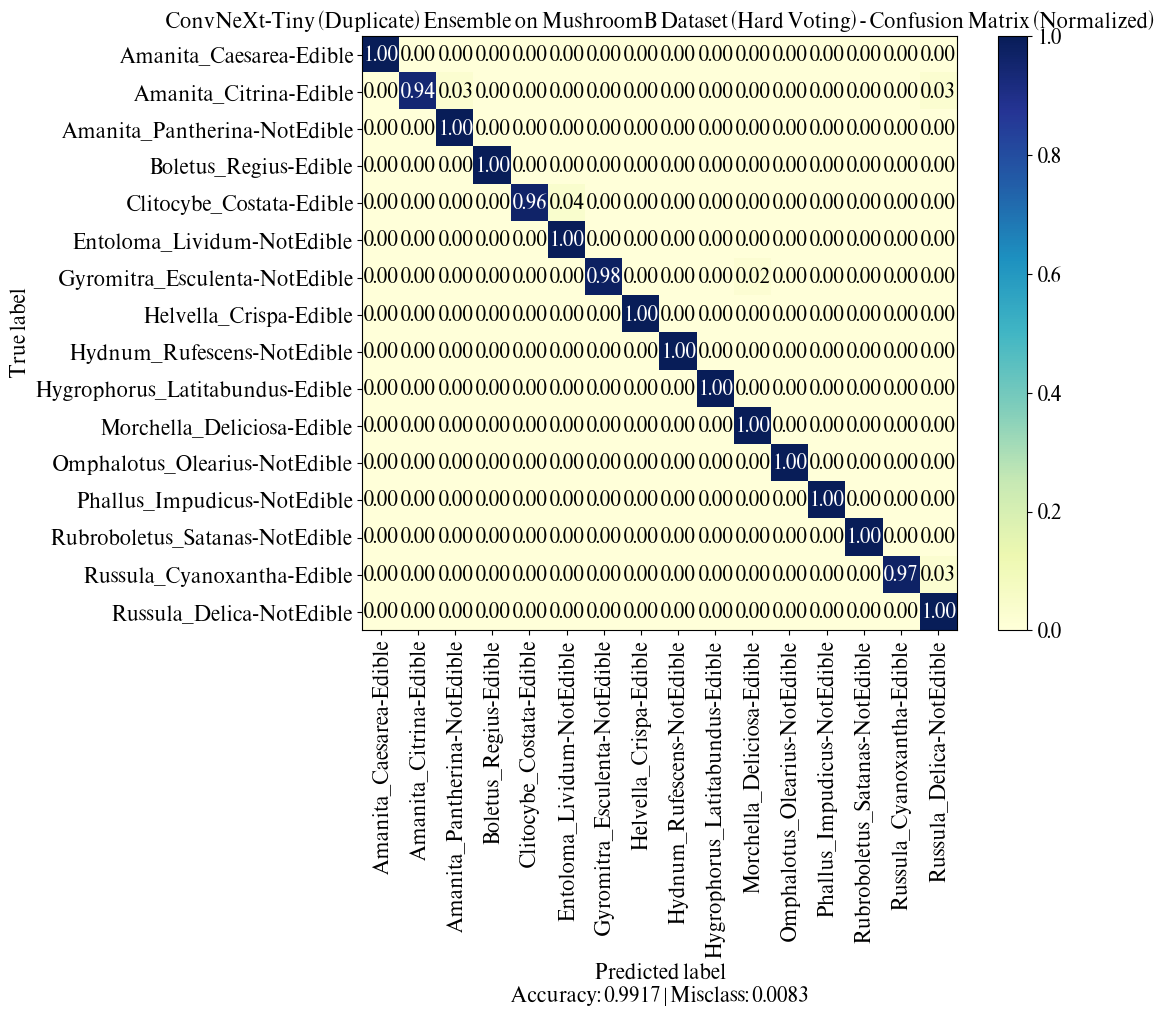




Voting Method: WEIGHTED
[*] Task Type: Multiclass | Average: macro
[Logs] Saved Metrics to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble_addition/weighted/weighted_test_perf_best_weight.csv
                                 precision    recall  f1-score   support

        Amanita_Caesarea-Edible     1.0000    1.0000    1.0000        46
         Amanita_Citrina-Edible     1.0000    0.9429    0.9706        35
   Amanita_Pantherina-NotEdible     0.9851    1.0000    0.9925        66
          Boletus_Regius-Edible     1.0000    1.0000    1.0000        26
       Clitocybe_Costata-Edible     1.0000    0.9630    0.9811        27
     Entoloma_Lividum-NotEdible     0.9615    1.0000    0.9804        25
  Gyromitra_Esculenta-NotEdible     1.0000    0.9778    0.9888        45
         Helvella_Crispa-Edible     1.0000    1.0000    1.0000        62
     Hydnum_Rufescens-NotEdible     1.0000    1.0000    1.0000        31
Hygrophorus_Lati

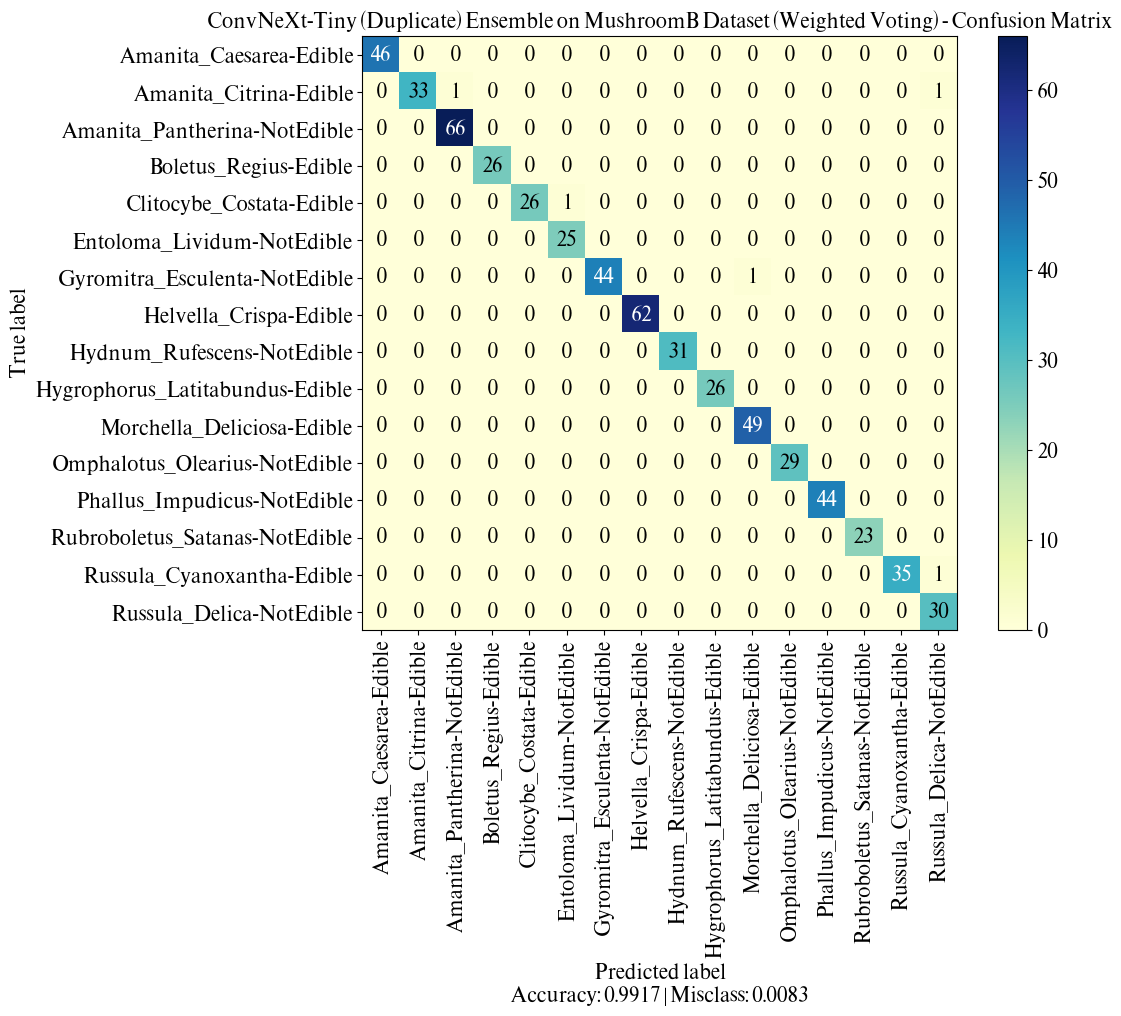

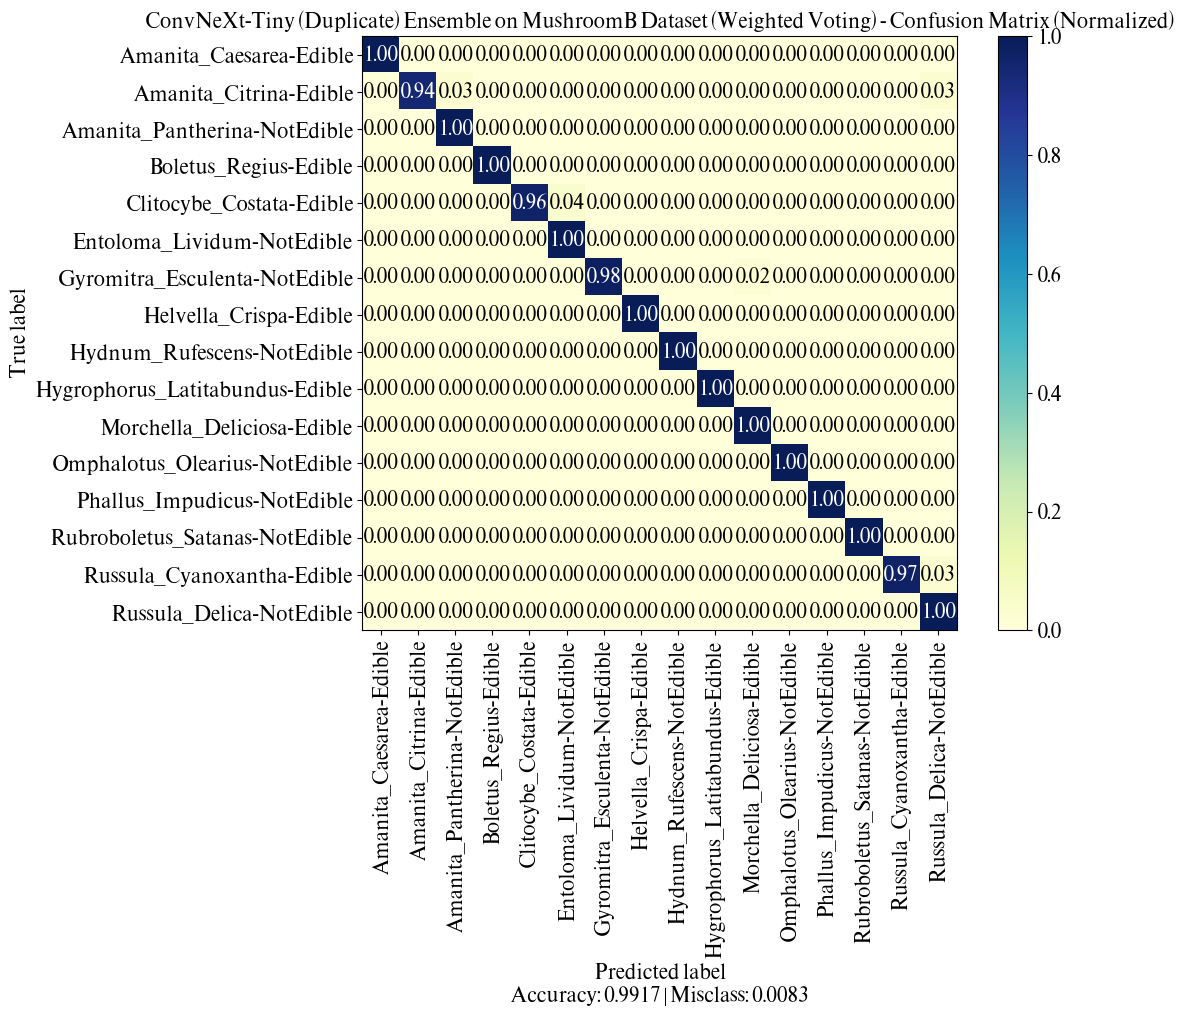

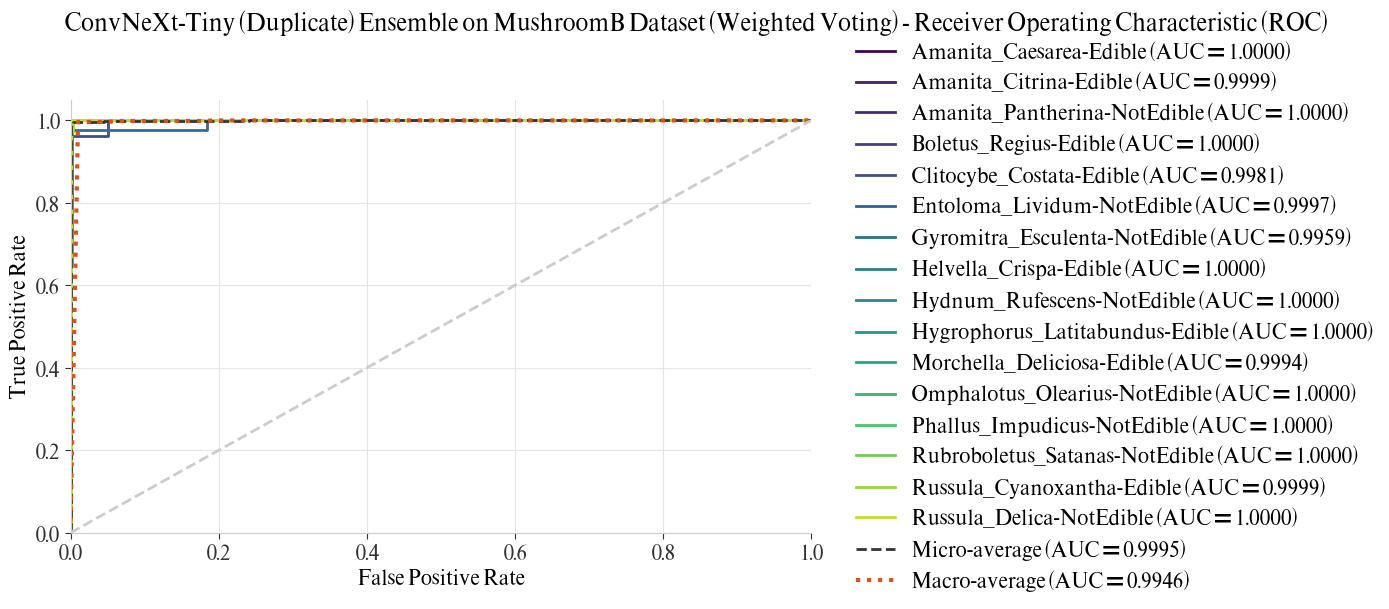




----------------------------------------------------------------------------------------------------
Ensemble Voting Comparison on Test Set (5 models):
         Method     loss  accuracy       f1  precision   recall  n_models  Aggregation Latency (ms/img)  Inference Latency (ms/img)  Total Latency (ms/img)
    Soft Voting 0.057392  0.991667 0.991057   0.991507 0.990989         5                      0.000080                    8.601436                8.601516
    Hard Voting      NaN  0.991667 0.991057   0.991507 0.990989         5                      0.000754                    8.601436                8.602190
Weighted Voting 0.057418  0.991667 0.991057   0.991507 0.990989         5                      0.000189                    8.601436                8.601624
----------------------------------------------------------------------------------------------------
[Logs] Saved Voting Comparison to: /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3

In [4]:
voting_comparison_df, voting_results = ensembleVoting.compare_voting_strategies(
    base_dir=add_model_dir,
    n_splits=add_config['n_folds'],
    weight_type=add_config['weight_type'],
    task=add_config['task'],
    average=add_config['average'],
    title=f'{add_model_name} Ensemble on {add_dataset_name} Dataset',
    cm_figsize=(12, 10),
    roc_figsize=(14, 6),
    **add_plot_kwargs,
)

##### **Voting weights (from validation accuracy)**

In [5]:
voting_weights_df = pd.read_csv(f"{add_model_dir}/ensemble_addition/voting_weights_{add_config['weight_type']}_weight.csv")
display(voting_weights_df.style.hide(axis="index"))

Fold,val_accuracy,weight
Fold 1,0.987603,0.199168
Fold 2,0.987603,0.199168
Fold 3,0.993789,0.200415
Fold 4,0.997930,0.201251
Fold 5,0.991718,0.199998


##### **Performance on Test Set (Voting comparison, latency in ms/img)**

In [6]:
display(voting_comparison_df.style.hide(axis="index"))

Method,loss,accuracy,f1,precision,recall,n_models,Aggregation Latency (ms/img),Inference Latency (ms/img),Total Latency (ms/img)
Soft Voting,0.057392,0.991667,0.991057,0.991507,0.990989,5,0.000080,8.601436,8.601516
Hard Voting,nan,0.991667,0.991057,0.991507,0.990989,5,0.000754,8.601436,8.602190
Weighted Voting,0.057418,0.991667,0.991057,0.991507,0.990989,5,0.000189,8.601436,8.601624


##### **McNemar's test (Baseline vs Proposed)**

ConvNeXt-T vs Modify

[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v1_MushroomB/ensemble
[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble
[*] Aligned 600 test samples (Filepaths and true labels verified)

----------------------------------------------------------------------------------------------------
McNemar's Test: ConvNeXt-Tiny (Duplicate) vs ConvNeXt-Tiny (Cleaning) (N = 600)
                                     ConvNeXt-Tiny (Cleaning) Correct  ConvNeXt-Tiny (Cleaning) Incorrect
ConvNeXt-Tiny (Duplicate) Correct                                 593                                   2
ConvNeXt-Tiny (Duplicate) Incorrect                                 1                                   4

Chi-square = 0.0000 | p-value = 1 | Exact p-value = 1
alpha = 0.05 -> Fail to reject H0 (no significant difference)
-------------------------------------------

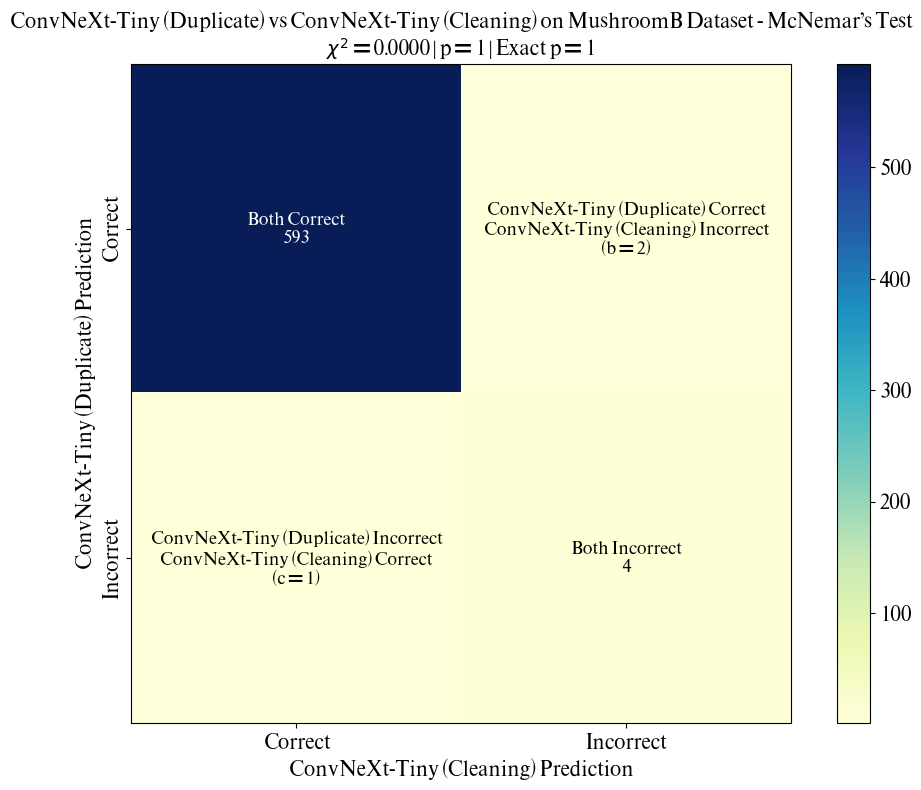

In [7]:
mcnemar_result_df, mcnemar_aligned_df = mcnemarTest.compare_mcnemar(
    baseline_model_dir=mc_baseline_model_dir,
    proposed_model_dir=mc_proposed_model_dir,
    baseline_name=mc_baseline_name,
    proposed_name=mc_proposed_name,
    alpha=mc_alpha,
    title=f'{mc_proposed_name} vs {mc_baseline_name} on {add_dataset_name} Dataset',
    figsize=(10, 8),
    **add_plot_kwargs,
)

##### **McNemar's test result**

In [8]:
display(mcnemar_result_df.style.hide(axis="index"))

Baseline,Proposed,N,Baseline Accuracy,Proposed Accuracy,Accuracy Diff (pp),Both Correct,"b (Proposed Correct, Baseline Incorrect)","c (Proposed Incorrect, Baseline Correct)",Both Incorrect,Chi-square,p-value,Exact p-value,Alpha,Significant
ConvNeXt-Tiny (Cleaning),ConvNeXt-Tiny (Duplicate),600,0.990000,0.991667,0.166667,593,2,1,4,0.000000,1.000000,1.000000,0.050000,False


##### **Disagreement samples (Only one model is correct)**

In [9]:
mcnemar_aligned_df[mcnemar_aligned_df['Baseline_Correct'] != mcnemar_aligned_df['Proposed_Correct']]

,Filepaths,True_Index,True_Label,Baseline_Pred_Index,Baseline_Pred_Label,Proposed_Pred_Index,Proposed_Pred_Label,Baseline_Correct,Proposed_Correct
59,/content/MushroomB/test/Amanita_Citrina-Edible...,1,Amanita_Citrina-Edible,1,Amanita_Citrina-Edible,15,Russula_Delica-NotEdible,True,False
183,/content/MushroomB/test/Clitocybe_Costata-Edib...,4,Clitocybe_Costata-Edible,11,Omphalotus_Olearius-NotEdible,4,Clitocybe_Costata-Edible,False,True
348,/content/MushroomB/test/Hydnum_Rufescens-NotEd...,8,Hydnum_Rufescens-NotEdible,0,Amanita_Caesarea-Edible,8,Hydnum_Rufescens-NotEdible,False,True


##### **Duplicate Recheck**

In [10]:
# แตกไฟล์ split และโหลด hash group ของภาพซ้ำ
import zipfile
import numpy as np

dup_variant = 'KEEP_DUP'  # variant ของ notebook นี้
clean_model_dir = get_model_dir('convnext_tiny_224_r1_v1', weights_root='modelWeights')  # CLEAN
data_drive_dir = f'{add_drive_dir}/data/{add_dataset_name}'
dup_check_dir = f'{add_model_dir}/ensemble_addition/duplicate_check'
os.makedirs(dup_check_dir, exist_ok=True)

def extract_split(zip_name):
    out_dir = f'/content/dup_check/{zip_name}'
    if not os.path.exists(out_dir):
        with zipfile.ZipFile(f'{data_drive_dir}/{zip_name}.zip', 'r') as zip_ref:
            zip_ref.extractall(out_dir)
    return out_dir

splits = {'CLEAN': extract_split(f'{add_dataset_name}_SPLIT'),
          dup_variant: extract_split(f'{add_dataset_name}_SPLIT_{dup_variant}')}

# hash group ของภาพซ้ำจากขั้นตอน curation เดิม
dup_df = pd.concat([pd.read_csv(f'{data_drive_dir}/imagesQuarantine/{add_dataset_name}_{r}_DUPLICATES.csv', dtype=str)
                    for r in ['INTRA', 'INTER']], ignore_index=True)
groups_of, members_of = {}, {}
for label, filename, group in zip(dup_df['label'], dup_df['filename'], dup_df['hash_group']):
    groups_of.setdefault((label, filename), set()).add(group)
    members_of.setdefault(group, set()).add((label, filename))
print(f'[Logs] Extracted {list(splits.values())} | duplicate hash groups: {len(members_of)}')

[Logs] Extracted ['/content/dup_check/MushroomB_SPLIT', '/content/dup_check/MushroomB_SPLIT_KEEP_DUP'] | duplicate hash groups: 18


In [11]:
# นับภาพ test ที่มีภาพซ้ำใน train และตรวจภาพที่ผลต่างจาก CLEAN (ทั้งสองฝั่ง)
def image_keys(folder):
    return {(os.path.basename(root), f) for root, _, files in os.walk(folder) for f in files}

def to_key(path):
    parts = str(path).replace('\\', '/').split('/')
    return (parts[-2], parts[-1])

def train_duplicates(key, train_keys):
    """ภาพใน train ที่อยู่ hash group เดียวกับภาพ test"""
    return sorted(({m for g in groups_of.get(key, set()) for m in members_of[g]} - {key}) & train_keys)

# ภาพ test ทั้งหมดที่มีภาพซ้ำอยู่ใน train
split_keys, leak_rows = {}, []
for name, d in splits.items():
    train_keys, test_keys = image_keys(f'{d}/remain'), image_keys(f'{d}/test')
    split_keys[name] = (train_keys, test_keys)
    leak_rows.append({'split': name, 'train_images': len(train_keys), 'test_images': len(test_keys),
                      'test_with_duplicate_in_train': sum(bool(train_duplicates(k, train_keys)) for k in test_keys)})
assert split_keys['CLEAN'][1] == split_keys[dup_variant][1], '[Error] Test sets of CLEAN and the variant differ.'
leak_df = pd.DataFrame(leak_rows)
leak_df.to_csv(f'{dup_check_dir}/test_duplicates_in_train.csv', index=False)
display(leak_df)

# ภาพที่ผลต่างจาก CLEAN
aligned = mcnemarTest.align_predictions(mcnemarTest.load_predictions(clean_model_dir), mcnemarTest.load_predictions(add_model_dir))
aligned['key'] = aligned['Filepaths'].map(to_key)
assert set(aligned['key']) == split_keys[dup_variant][1], '[Error] Predictions do not match the test set.'
variant_train = split_keys[dup_variant][0]
aligned['train_duplicates'] = aligned['key'].map(lambda k: train_duplicates(k, variant_train))

directions = {
    f'{dup_variant}_correct_only': aligned['Proposed_Correct'] & ~aligned['Baseline_Correct'],
    'CLEAN_correct_only': aligned['Baseline_Correct'] & ~aligned['Proposed_Correct'],
}
summary_rows, dup_pairs = [], {}
for direction, mask in directions.items():
    sub = aligned[mask].sort_values('key').reset_index(drop=True)
    has_dup = sub['train_duplicates'].map(bool)
    summary_rows.append({'direction': direction, 'n_images': len(sub), 'with_duplicate_in_train': int(has_dup.sum()),
                         'with_duplicate_in_train_%': round(100 * has_dup.mean(), 2) if len(sub) else np.nan})
    dup_pairs[direction] = sub[has_dup].reset_index(drop=True)
    pd.DataFrame({
        'label': [k[0] for k in sub['key']],
        'filename': [k[1] for k in sub['key']],
        'hash_group': ['|'.join(sorted(groups_of.get(k, set()))) for k in sub['key']],
        'CLEAN_pred': sub['Baseline_Pred_Label'],
        f'{dup_variant}_pred': sub['Proposed_Pred_Label'],
        'train_duplicates': ['|'.join(f'{l}/{f}' for l, f in d) for d in sub['train_duplicates']],
    }).to_csv(f'{dup_check_dir}/{direction}.csv', index=False)

dup_summary_df = pd.DataFrame(summary_rows)
dup_summary_df.to_csv(f'{dup_check_dir}/summary.csv', index=False)
print(f'[Logs] Saved duplicate check to {dup_check_dir}')
display(dup_summary_df)

,split,train_images,test_images,test_with_duplicate_in_train
0,CLEAN,2399,600,0
1,KEEP_DUP,2417,600,6


[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v1_MushroomB/ensemble
[*] Loaded 600 predictions from /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble
[Logs] Saved duplicate check to /content/drive/MyDrive/projectMushroom/modelWeights/MushroomB/convnext_tiny_224_r1_v3_MushroomB/ensemble_addition/duplicate_check


,direction,n_images,with_duplicate_in_train,with_duplicate_in_train_%
0,KEEP_DUP_correct_only,2,0,0.0
1,CLEAN_correct_only,1,0,0.0


Test images with a duplicate in train (KEEP_DUP): 6


KEEP_DUP,correct
CLEAN,
correct,6


,label,short_id,filename,train_duplicates,CLEAN_pred,KEEP_DUP_pred,CLEAN_correct,KEEP_DUP_correct
0,Amanita_Pantherina-NotEdible,Amanita_Pantherina_0128,Amanita_Pantherina_0128.jpg,Amanita_Pantherina-NotEdible/Amanita_Pantherin...,Amanita_Pantherina-NotEdible,Amanita_Pantherina-NotEdible,True,True
1,Amanita_Pantherina-NotEdible,Amanita_Pantherina_0144,Amanita_Pantherina_0144.jpg,Amanita_Pantherina-NotEdible/Amanita_Pantherin...,Amanita_Pantherina-NotEdible,Amanita_Pantherina-NotEdible,True,True
2,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas_0004,Rubroboletus_Satanas_0004.jpg,Rubroboletus_Satanas-NotEdible/Rubroboletus_Sa...,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas-NotEdible,True,True
3,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas_0009,Rubroboletus_Satanas_0009.jpg,Rubroboletus_Satanas-NotEdible/Rubroboletus_Sa...,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas-NotEdible,True,True
4,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas_0014,Rubroboletus_Satanas_0014.jpg,Rubroboletus_Satanas-NotEdible/Rubroboletus_Sa...,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas-NotEdible,True,True
5,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas_0103,Rubroboletus_Satanas_0103.jpg,Rubroboletus_Satanas-NotEdible/Rubroboletus_Sa...,Rubroboletus_Satanas-NotEdible,Rubroboletus_Satanas-NotEdible,True,True


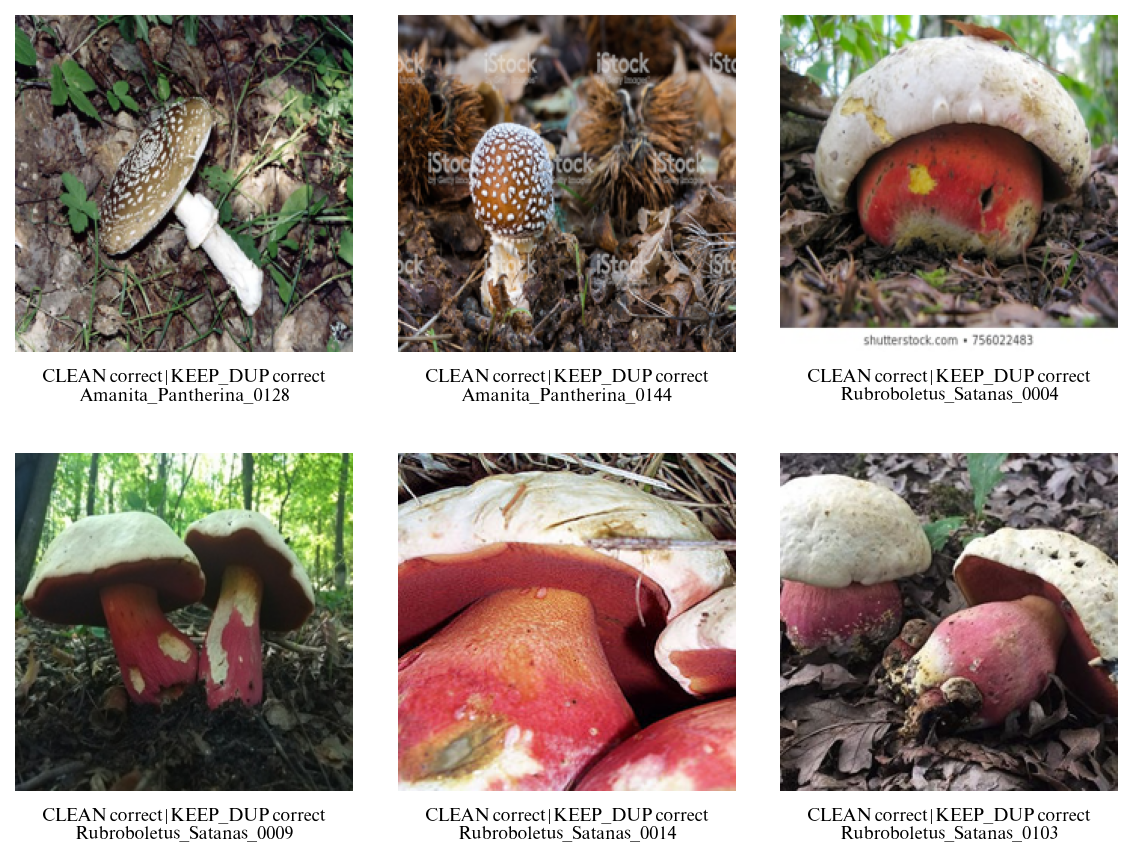

In [12]:
leak = aligned[aligned['train_duplicates'].map(bool)].sort_values('key').reset_index(drop=True)
result = lambda ok: 'correct' if ok else 'incorrect'

short_ids = [f.split('_')[0] for _, f in leak['key']]
if len(set(short_ids)) != len(leak):
    short_ids = [os.path.splitext(f)[0] for _, f in leak['key']]

leak_detail_df = pd.DataFrame({
    'label': [k[0] for k in leak['key']],
    'short_id': short_ids,
    'filename': [k[1] for k in leak['key']],
    'train_duplicates': ['|'.join(f'{l}/{f}' for l, f in d) for d in leak['train_duplicates']],
    'CLEAN_pred': leak['Baseline_Pred_Label'],
    f'{dup_variant}_pred': leak['Proposed_Pred_Label'],
    'CLEAN_correct': leak['Baseline_Correct'],
    f'{dup_variant}_correct': leak['Proposed_Correct'],
})
leak_detail_df.to_csv(f'{dup_check_dir}/test_duplicates_in_train_detail.csv', index=False)
print(f'Test images with a duplicate in train ({dup_variant}): {len(leak)}')
display(pd.crosstab(leak['Baseline_Correct'].map(result), leak['Proposed_Correct'].map(result),
                    rownames=['CLEAN'], colnames=[dup_variant]))
display(leak_detail_df)

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

leak_fig_df = pd.DataFrame({
    'filepaths': [f'{splits[dup_variant]}/test/{l}/{f}' for l, f in leak['key']],
    'caption': [f'CLEAN {result(b)} | {dup_variant} {result(p)}\n{s}'
                for s, b, p in zip(short_ids, leak['Baseline_Correct'], leak['Proposed_Correct'])],
})
for k, start in enumerate(range(0, len(leak_fig_df), 9), start=1):
    visualization.vis_images(df=leak_fig_df.iloc[start:start + 9], filepaths_col='filepaths', label_col='caption',
                             n_rows=3, n_cols=3, target_size=(224, 224), figsize=(15, 6.5), fontsize=8, title=None,
                             save_path=f'{dup_check_dir}/test_duplicates_in_train_{k}')